# Parametric 3D CAD Model Generation (`kaleidocycle.cad`)

This notebook demonstrates how to generate 3D-printable **Twisted Plate** Kaleidocycle parts and assemblies using the optional `build123d` backend (`kaleidocycle.cad`).

The geometry is parameterized by:
- `torsion_angle`: twist angle between the two hinge axes (radians by default, or degrees with `degrees=True`)
- `ribbon_width`: length along each hinge axis (mm; default 43)
- `edge_length`: center-to-center distance between bottom and top hinge axes (mm)
- `with_ring`: whether to include the captive print-in-place ring (`False` by default)
- Additional hinge and clearance parameters (`body_thickness`, `hinge_diameter`, `hinge_gap`, `gap`, `num_knuckles`, etc.)
- `hinge_type`: `"pin"` (separate octagonal pins, default) or `"cone"` (snap-in cone pivots)
- Hinge fit (`pin_diameter`, `pin_fit_clearance`, `pin_clearance`, `pin_core_diameter`, `pin_chamfer`; `cone_diameter`, `cone_angle`, `snap_gap`)

Both hinge types reproduce NovemberKou's printed designs:
- `hinge_type="pin"` (*Material-saving Design*): separately printed octagonal hinge pins. The bottom knuckles of a unit hold the pin (0.09 mm radial clearance at its corners, a snug push fit on most printers), and the top knuckles of the neighbouring unit rotate on it (0.3 mm radial clearance); the knuckles are 0.4 mm apart along the axis. These clearances are wider than the reference design's, which were too tight in a test print.
- `hinge_type="cone"` (*Twisted Plate with Ring*): no separate parts. The outer bottom knuckles carry 60° cones that snap into conical sockets in the neighbour's outer top knuckles; the socketed knuckles keep a 2.25 mm gap on their inner side so they can flex past the cone tips.

Every export checks the parts for contacts automatically (`kaleidocycle.cad_check`): the hinge fit, and for a kaleidocycle every pair of links through a full rotation (traced with the integrable flow). Contacts closer than `min_clearance` (0.4 mm) raise a `ClearanceWarning`.

All choices — the ring, how it is constructed and the print geometry — are made in the **Parameters** cell; the rest of the notebook follows them. The defaults reproduce the anti-oriented $N=7$ ring of minimum torsion with 43 mm ribbons and pin hinges.

In [5]:
%matplotlib widget

import struct
from pathlib import Path

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np

from kaleidocycle import (
    ConstraintConfig,
    Kaleidocycle,
    SolverOptions,
    TwistedPlateConfig,
    build_twisted_plate_parts,
    check_kaleidocycle_clearance,
    closed_elliptic_family,
    critical_multiplier,
    default_objective,
    export_print_plate,
    export_twisted_plate,
    framed_polygon_from_binormals,
    load_sample,
    mirror,
    optimize_cycle,
    random_hinges,
    right_angle_family,
    twisted_plate_from_kaleidocycle,
    variational_recurrence_residual,
)

output_dir = (
    Path("output")
    if Path.cwd().name == "notebooks"
    else Path("notebooks/output")
)
output_dir.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {output_dir.resolve()}")

Output directory: /Users/kaji/Library/CloudStorage/Dropbox/maple/Kaleidocycle/python/notebooks/output


## Parameters

Choose the ring, its construction and the print geometry here.

| `CONSTRUCTION` | Ring |
| --- | --- |
| `"optimise"` | Minimises `OBJECTIVE` under closure and constant torsion from a random start (`SEED`) with the SciPy solver `SOLVER`. `"auto"` is the objective `Kaleidocycle(N)` uses: for anti-oriented odd $N$ it maximises the mean hinge cosine, giving the minimum torsion angle. `TORSION_DEG` fixes the torsion angle; `None` leaves it free. |
| `"elliptic"` | The exact torsion-critical ring of the Jacobi elliptic family with winding $m$ = `WINDING` and closing index $j$ = `LEVEL`. $m=3$, $j=1$ is the principal family (the minimum torsion $\mu_N$, $N \ge 7$); $m = N/2$ is the right-angle circle ($\mu = \pi/2$, even $N$). The ring is oriented exactly when $m$ is even. `MIRROR = True` applies the mirror duality $B_n \mapsto (-1)^n B_n$: the torsion becomes $\pi - \mu$, and for odd $N$ the orientation flips. |
| `"sample"` | A built-in sample from `data/kaleidocycles/` (`SAMPLE`); its $N$ and orientation replace `N` and `ORIENTED`. |

The **hinge fit** values are the clearances that decide whether a printed pin goes in and how freely the hinge turns. The defaults suit most FDM printers; after a test print, raise `PIN_FIT_CLEARANCE` if the pin does not go in (lower it if the pin slides out), and raise `PIN_CLEARANCE`, `HINGE_GAP` or `GAP` if the hinge turns stiffly. `BODY_THICKNESS` sets the plate thickness: thicker plates print more reliably but bring links that do not share a hinge closer together, which the contact check in Section 2 reports.

Output files are named after the ring (the prefix is printed in Section 1), so different choices do not overwrite each other.

In [ ]:
# ---- Ring --------------------------------------------------------------------
N = 7  # number of links (tetrahedra)
ORIENTED = False  # False: anti-oriented Möbius ring (sign -1); True: oriented (+1)
CONSTRUCTION = "optimise"  # "optimise", "elliptic" or "sample"

# CONSTRUCTION = "optimise"
OBJECTIVE = "auto"  # "auto", "bending", "mean_cos", "neg_mean_cos", "torsion",
#                     "dipole" or "curvature_recursion"
TORSION_DEG = None  # None: free; a number fixes the torsion angle (degrees)
SOLVER = "trust-constr"  # constrained SciPy solver: "trust-constr" or "SLSQP"
MAXITER = 500
SEED = 42  # random initial configuration

# CONSTRUCTION = "elliptic"
WINDING = 3  # m: 3 <= m < N/2, or m = N/2 for the right-angle circle
LEVEL = 1  # j: 1 <= j <= (m - 1) // 2, or 1 <= j < N/4 when m = N/2
PHASE = 0.0  # position on the critical circle
MIRROR = False  # mirror dual: torsion pi - mu

# CONSTRUCTION = "sample"
SAMPLE = "mobius_k8_nonoriented"

# ---- Print geometry ----------------------------------------------------------
RIBBON_WIDTH = 33.0  # mm, length of a link along its hinge axes
EDGE_LENGTH = 29.0  # mm, distance between the two hinge axes of a link
BODY_THICKNESS = 2.4  # mm, plate thickness; thicker prints more reliably but
#                       brings links closer (see the contact check)
HINGE_TYPE = "pin"  # "pin": separate octagonal pins; "cone": snap-in cones
WITH_RING = False  # add the captive print-in-place ring to every link

# ---- Hinge fit (tune after a test print) -------------------------------------
PIN_FIT_CLEARANCE = 0.09  # mm, pin corners to the bores that hold it
PIN_CLEARANCE = 0.3  # mm, pin corners to the bores that turn on it
HINGE_GAP = None  # mm, axial gap between knuckles; None: 0.4 (pin), 0.2 (cone)
GAP = 0.4  # mm, mating knuckles to the plate edge bridged over them

## 1. Build the Kaleidocycle

The ring is built as chosen in **Parameters** and checked for closure and constant torsion. It is *torsion-critical* (its torsion angle is stationary among nearby closed rings) exactly when its curvatures satisfy the stationary recurrence $D_n(\kappa_{n-1}+\kappa_{n+1}) = \lambda\kappa_n$ with $\lambda = 2\cos\mu + E_2/N$; the cell prints the relative residual. The elliptic families, the optimised ring of minimum torsion and the Möbius samples are critical; a ring with a prescribed torsion generally is not. An optimised ring can also be degenerate, with two adjacent links folded flat onto each other (for example the bending minimiser of the oriented $N=8$ ring); the cell then says so, and the contact check reports the collision.

construction         : optimised (neg_mean_cos, torsion 80 deg, trust-constr, seed 42)
file prefix          : k7_anti_oriented_mu80
n                    : 7
oriented / sign      : False / -1
constant_torsion     : 1.3962634016 rad (80.000000 deg)
cos(torsion)         : 0.1736481777
is_closed / aligned  : True / True
recurrence lambda    : 0.3640519817
recurrence residual  : 1.438e+00 (relative)
torsion-critical     : False


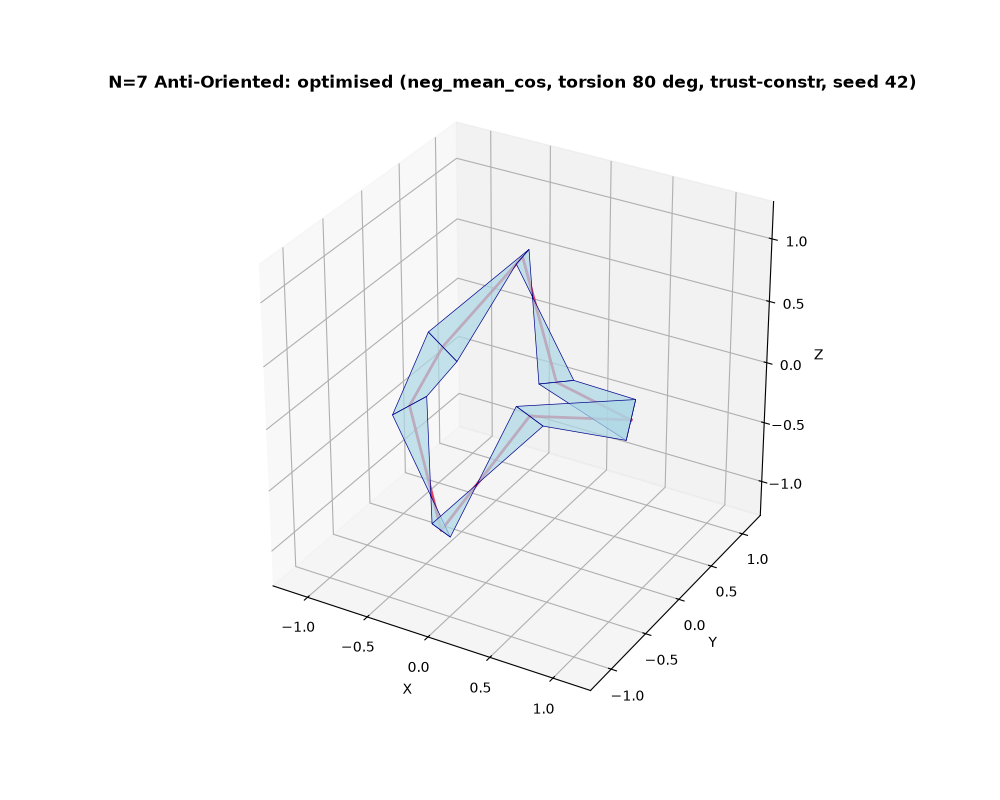

In [10]:
def build_ring():
    """Return the ring chosen in the Parameters cell and a description."""
    if CONSTRUCTION == "optimise":
        objective = default_objective(N, ORIENTED) if OBJECTIVE == "auto" else OBJECTIVE
        target = None if TORSION_DEG is None else float(np.cos(np.deg2rad(TORSION_DEG)))
        result = optimize_cycle(
            random_hinges(N, seed=SEED, oriented=ORIENTED).as_array(),
            ConstraintConfig(oriented=ORIENTED, constant_torsion=True),
            objective=objective,
            target_torsion=target,
            options=SolverOptions(maxiter=MAXITER, constraint_method=SOLVER),
        )
        torsion = "free torsion" if TORSION_DEG is None else f"torsion {TORSION_DEG} deg"
        label = f"optimised ({objective}, {torsion}, {SOLVER}, seed {SEED})"
        return Kaleidocycle(hinges=result.hinges, oriented=ORIENTED), label
    if CONSTRUCTION == "elliptic":
        if 2 * WINDING == N:
            family = right_angle_family(N, LEVEL)
        else:
            family = closed_elliptic_family(N, WINDING, LEVEL)
        hinges = family.binormals(phase=PHASE)
        oriented = family.sign == 1
        label = f"elliptic (m = {WINDING}, j = {LEVEL}, k = {family.modulus:.6f})"
        if MIRROR:
            hinges = mirror(hinges)
            oriented = oriented != (N % 2 == 1)
            label = "mirrored " + label
        if oriented != ORIENTED:
            raise ValueError(
                f"WINDING = {WINDING} with MIRROR = {MIRROR} gives an "
                f"{'oriented' if oriented else 'anti-oriented'} ring: set "
                f"ORIENTED = {oriented}, or change WINDING (oriented exactly "
                "when m is even) or MIRROR (which flips it for odd N)."
            )
        return Kaleidocycle(hinges=hinges, oriented=oriented), label
    if CONSTRUCTION == "sample":
        return load_sample(SAMPLE), f"sample {SAMPLE}"
    raise ValueError(f"unknown CONSTRUCTION {CONSTRUCTION!r}")


def file_prefix():
    """Name the output files after the ring."""
    if CONSTRUCTION == "sample":
        return SAMPLE
    prefix = f"k{kc.n}_{'oriented' if kc.oriented else 'anti_oriented'}"
    if CONSTRUCTION == "elliptic":
        return prefix + f"_m{WINDING}_j{LEVEL}" + ("_mirror" if MIRROR else "")
    if OBJECTIVE != "auto":
        prefix += f"_{OBJECTIVE}"
    if TORSION_DEG is not None:
        prefix += f"_mu{TORSION_DEG:g}"
    return prefix


kc, construction = build_ring()
prefix = file_prefix()

if not (kc.is_closed and kc.is_aligned) or kc.constant_torsion is None:
    raise RuntimeError(
        f"{construction} is not a closed constant-torsion ring. Try another "
        "SEED, SOLVER or MAXITER, or a feasible TORSION_DEG."
    )

cos_mean = float(np.mean(np.sum(kc.hinges[:-1] * kc.hinges[1:], axis=1)))
sign = 1 if kc.oriented else -1

print(f"construction         : {construction}")
print(f"file prefix          : {prefix}")
print(f"n                    : {kc.n}")
print(f"oriented / sign      : {kc.oriented} / {sign}")
print(
    f"constant_torsion     : {kc.constant_torsion:.10f} rad "
    f"({np.rad2deg(kc.constant_torsion):.6f} deg)"
)
print(f"cos(torsion)         : {cos_mean:.10f}")
print(f"is_closed / aligned  : {kc.is_closed} / {kc.is_aligned}")

# Stationary recurrence D[n](kappa[n-1] + kappa[n+1]) = lambda kappa[n] with
# lambda = 2 cos(mu) + E2/N: it holds exactly at torsion-critical rings.
try:
    fp = framed_polygon_from_binormals(kc.hinges)
except ValueError as error:
    print(
        f"torsion-critical     : not evaluated ({error}); two adjacent links "
        "fold flat onto each other"
    )
else:
    lam = critical_multiplier(fp.curvatures, cos_mean, sign=sign)
    residual = variational_recurrence_residual(fp.curvatures, lam, sign=sign)
    relative = float(np.linalg.norm(residual) / np.linalg.norm(fp.curvatures))
    print(f"recurrence lambda    : {lam:.10f}")
    print(f"recurrence residual  : {relative:.3e} (relative)")
    print(f"torsion-critical     : {relative < 1e-4}")

orientation = "Oriented" if kc.oriented else "Anti-Oriented"
ax = kc.plot(title=f"N={kc.n} {orientation}: {construction}", show_curve=True)
plt.show()

## 2. Export 3D-Printable Models

`twisted_plate_from_kaleidocycle()` turns the ring's torsion angle into a twisted-plate link with the chosen print geometry. The next cell writes three models, named after the prefix printed in Section 1:
- one link, `<prefix>_unit` (`.stl`, `.step`);
- all $N$ links on one print plate, `<prefix>_plate` (`.3mf`, with an `.stl` layout preview);
- the closed ring assembled, `<prefix>_assembly` (`.stl`, `.step`).

`_cone` and `_with_ring` are appended to the names for cone hinges and the captive ring.

The `.3mf` files are plain 3MF (core specification) without slicer project settings: Bambu Studio, OrcaSlicer, and PrusaSlicer open them as geometry and keep the printer, filament, and process presets you currently have selected. Each unit is one object (with `plate` and `ring` parts when `with_ring=True`), laid out around the centre of a 256 mm bed (`bed_center=(128, 128)` by default).

With pin hinges, print plates also carry one hinge pin per unit (object `hinge_pin`, lying flat so that it prints without support), and the assembly shows the pins in place. Push each pin through the bottom knuckles of one unit and the interleaved top knuckles of the next; the chamfered ends ease insertion.

Every export checks for contacts first and warns if links touch. For the default $N=7$ ring with 2.4 mm plates, a 43 mm ribbon keeps links two apart at least 0.66 mm from each other through the whole rotation, while at 44–45 mm they touch near the centre of the ring (see the clearance reports below).

In [11]:
plate_options = {
    "ribbon_width": RIBBON_WIDTH,
    "edge_length": EDGE_LENGTH,
    "body_thickness": BODY_THICKNESS,
    "with_ring": WITH_RING,
    "hinge_type": HINGE_TYPE,
    "pin_fit_clearance": PIN_FIT_CLEARANCE,
    "pin_clearance": PIN_CLEARANCE,
    "hinge_gap": HINGE_GAP,
    "gap": GAP,
}
suffix = ("_cone" if HINGE_TYPE == "cone" else "") + ("_with_ring" if WITH_RING else "")


def output_path(kind: str, extension: str) -> Path:
    return output_dir / f"{prefix}_{kind}{suffix}.{extension}"


plate_cfg = twisted_plate_from_kaleidocycle(kc, **plate_options)
print(plate_cfg)
print(f"torsion_degrees = {plate_cfg.torsion_degrees:.6f} deg")

exported_files = [
    export_twisted_plate(output_path("unit", "stl"), plate_cfg),
    export_twisted_plate(output_path("unit", "step"), plate_cfg),
    kc.export_twisted_plate(output_path("plate", "3mf"), **plate_options),
    export_print_plate(output_path("plate", "stl"), kc, **plate_options),
    kc.export_twisted_plate(output_path("assembly", "stl"), assembly=True, **plate_options),
    kc.export_twisted_plate(output_path("assembly", "step"), assembly=True, **plate_options),
]

for path in exported_files:
    print(f"Exported {path.name:48s} ({path.stat().st_size:,} bytes)")

TwistedPlateConfig(torsion_angle=1.3962634015954636, ribbon_width=33.0, edge_length=29.0, body_thickness=2.4, hinge_type='pin', hinge_diameter=None, hinge_gap=None, gap=0.4, num_knuckles=5, pin_diameter=4.0, pin_fit_clearance=0.07, pin_clearance=0.3, pin_core_diameter=1.8, pin_chamfer=0.5, cone_diameter=4.0, cone_angle=60.0, snap_gap=2.25, with_ring=False, cut_slits=None, ring_diameter=None, ring_width=2.0, ring_gap=0.5, slit_rail_height=2.0, loft_slices=25)
torsion_degrees = 80.000000 deg


/var/folders/g6/d1w60lkx7f315zbszv_nvklw0000gn/T/ipykernel_72430/2774347897.py:26: ClearanceWarning: Clearance check (pin hinges, required 0.40 mm between non-adjacent links): 21 contact(s)
  motion          : mKdV2 flow, cycle of 210 steps (210 poses checked)
  hinge fit       : 0.30 mm
  adjacent links  : 0.00 mm (away from the hinge)
  non-adjacent    : 0.00 mm
  - adjacent: link 0 / link 1, overlap 7.09 mm^3 at 82% of the cycle
  - non-adjacent: link 0 / link 2, overlap 36.35 mm^3 at 85% of the cycle
  - non-adjacent: link 0 / link 3, overlap 3.22 mm^3 at 4% of the cycle
  - non-adjacent: link 0 / link 4, overlap 10.28 mm^3 at 23% of the cycle
  - non-adjacent: link 0 / link 5, overlap 32.65 mm^3 at 16% of the cycle
  - adjacent: link 0 / link 6, overlap 7.11 mm^3 at 53% of the cycle
  - adjacent: link 1 / link 2, overlap 7.12 mm^3 at 5% of the cycle
  - non-adjacent: link 1 / link 3, overlap 42.06 mm^3 at 2% of the cycle
  - non-adjacent: link 1 / link 4, overlap 10.27 mm^3 at 37%

Exported k7_anti_oriented_mu80_unit.stl                   (436,184 bytes)
Exported k7_anti_oriented_mu80_unit.step                  (300,447 bytes)
Exported k7_anti_oriented_mu80_plate.3mf                  (118,713 bytes)
Exported k7_anti_oriented_mu80_plate.stl                  (3,246,484 bytes)
Exported k7_anti_oriented_mu80_assembly.stl               (3,362,084 bytes)
Exported k7_anti_oriented_mu80_assembly.step              (3,026,514 bytes)


In [5]:
if plate_cfg.hinge_type == "pin":
    print(
        f"hinge pin      : octagon {plate_cfg.pin_diameter:.2f} mm corner-to-corner, "
        f"{2 * plate_cfg.pin_inradius:.2f} mm across flats, "
        f"{plate_cfg.ribbon_width:.1f} mm long"
    )
    print(
        f"bottom knuckles: bore {2 * plate_cfg.fixed_bore_radius:.2f} mm, "
        f"{plate_cfg.pin_fit_clearance:.2f} mm clearance (hold the pin)"
    )
    print(
        f"top knuckles   : bore {2 * plate_cfg.free_bore_radius:.2f} mm, "
        f"{plate_cfg.pin_clearance:.2f} mm clearance (turn on the pin)"
    )
else:
    print(
        f"cone hinge     : {plate_cfg.cone_diameter:.1f} mm base, "
        f"{plate_cfg.cone_angle:.0f} deg half-angle, {plate_cfg.cone_height:.3f} mm high"
    )
    print(
        f"snap fit       : deflection {plate_cfg.snap_deflection:.2f} mm "
        f"into a {plate_cfg.snap_gap:.2f} mm gap"
    )
print(
    f"knuckles       : diameter {plate_cfg.resolved_hinge_diameter:.1f} mm, "
    f"axial gap {plate_cfg.resolved_hinge_gap:.1f} mm, "
    f"{plate_cfg.gap:.1f} mm below the mating plate edge"
)

hinge pin      : octagon 4.00 mm corner-to-corner, 3.70 mm across flats, 43.0 mm long
bottom knuckles: bore 4.20 mm, 0.10 mm clearance (hold the pin)
top knuckles   : bore 4.60 mm, 0.30 mm clearance (turn on the pin)
knuckles       : diameter 7.0 mm, axial gap 0.4 mm, 0.4 mm below the mating plate edge


### Contact check through the rotation

`check_kaleidocycle_clearance()` (run automatically by the exports above) moves the ring of links through one full rotation and reports the smallest clearances. Below: the chosen settings, the other hinge type, and a ribbon 2 mm wider, which shows the margin. A ring that is not torsion-critical may not return to its starting pose under the flow; the report then says that only the given pose was checked.

In [6]:
other_hinge = "cone" if HINGE_TYPE == "pin" else "pin"
for width, hinge_type in (
    (RIBBON_WIDTH, HINGE_TYPE),
    (RIBBON_WIDTH, other_hinge),
    (RIBBON_WIDTH + 2.0, HINGE_TYPE),
):
    report = check_kaleidocycle_clearance(
        kc,
        ribbon_width=width,
        edge_length=EDGE_LENGTH,
        body_thickness=BODY_THICKNESS,
        with_ring=WITH_RING,
        hinge_type=hinge_type,
        pin_fit_clearance=PIN_FIT_CLEARANCE,
        pin_clearance=PIN_CLEARANCE,
        hinge_gap=HINGE_GAP,
        gap=GAP,
    )
    print(f"ribbon_width = {width:g} mm, hinge_type = {hinge_type!r}")
    print(report.summary())
    print()

ribbon_width = 43 mm, hinge_type = 'pin'
Clearance check (pin hinges, required 0.40 mm between non-adjacent links): OK
  motion          : mKdV2 flow, cycle of 239 steps (239 poses checked)
  hinge fit       : 0.30 mm
  adjacent links  : more than 3.0 mm (away from the hinge)
  non-adjacent    : 0.66 mm



ribbon_width = 43 mm, hinge_type = 'cone'
Clearance check (cone hinges, required 0.40 mm between non-adjacent links): OK
  motion          : mKdV2 flow, cycle of 239 steps (239 poses checked)
  hinge fit       : 0.17 mm
  adjacent links  : more than 3.0 mm (away from the hinge)
  non-adjacent    : 0.81 mm



ribbon_width = 45 mm, hinge_type = 'pin'
Clearance check (pin hinges, required 0.40 mm between non-adjacent links): 7 contact(s)
  motion          : mKdV2 flow, cycle of 239 steps (239 poses checked)
  hinge fit       : 0.30 mm
  adjacent links  : more than 3.0 mm (away from the hinge)
  non-adjacent    : 0.00 mm
  - non-adjacent: link 0 / link 2, overlap 1.11 mm^3 at 17% of the cycle
  - non-adjacent: link 0 / link 5, overlap 0.04 mm^3 at 59% of the cycle
  - non-adjacent: link 1 / link 3, overlap 1.31 mm^3 at 95% of the cycle
  - non-adjacent: link 1 / link 6, overlap 0.42 mm^3 at 38% of the cycle
  - non-adjacent: link 2 / link 4, overlap 2.05 mm^3 at 76% of the cycle
  - non-adjacent: link 3 / link 5, overlap 0.14 mm^3 at 2% of the cycle
  - non-adjacent: link 4 / link 6, overlap 0.08 mm^3 at 30% of the cycle



## 3. Direct Parametric Customization Examples

You can also specify `torsion_angle`, `ribbon_width`, `edge_length`, `num_knuckles`, `with_ring`, and wall/clearance parameters directly without constructing a `Kaleidocycle`.

In [7]:
custom_configs = {
    "compact_no_ring": TwistedPlateConfig(
        torsion_angle=np.deg2rad(60.0),
        ribbon_width=36.0,
        edge_length=24.0,
        body_thickness=1.6,
        num_knuckles=3,
        with_ring=False,
    ),
    "wide_with_ring": TwistedPlateConfig(
        torsion_angle=np.deg2rad(80.0),
        ribbon_width=55.0,
        edge_length=35.0,
        body_thickness=2.0,
        with_ring=True,
    ),
}

for name, cfg in custom_configs.items():
    parts = build_twisted_plate_parts(cfg)
    volumes = {k: round(v.volume, 2) for k, v in parts.items()}
    valid = {k: v.is_valid() for k, v in parts.items()}
    bbox = parts["plate"].bounding_box()
    print(
        f"{name:16s} | torsion={cfg.torsion_degrees:5.1f} deg | "
        f"W={cfg.ribbon_width:4.1f} mm | d={cfg.edge_length:4.1f} mm | "
        f"parts={volumes} mm^3 | valid={valid} | "
        f"Z=[{bbox.min.Z:.2f}, {bbox.max.Z:.2f}]"
    )

custom_stl = export_twisted_plate(
    output_dir / "custom_60deg_W36_d24.stl",
    torsion_angle=60.0,
    ribbon_width=36.0,
    edge_length=24.0,
    num_knuckles=3,
    degrees=True,
)
print(
    f"Exported custom model: {custom_stl.name} ({custom_stl.stat().st_size:,} bytes)"
)

compact_no_ring  | torsion= 60.0 deg | W=36.0 mm | d=24.0 mm | parts={'plate': 1774.79} mm^3 | valid={'plate': True} | Z=[-0.00, 30.70]


wide_with_ring   | torsion= 80.0 deg | W=55.0 mm | d=35.0 mm | parts={'plate': 3996.1, 'ring': 219.91} mm^3 | valid={'plate': True, 'ring': True} | Z=[-0.00, 41.70]


Exported custom model: custom_60deg_W36_d24.stl (314,584 bytes)


## 4. 3D Mesh Preview of Exported STL Files

Read triangles directly from the binary `.stl` files written in Section 2: one link, the print plate and the assembled ring.

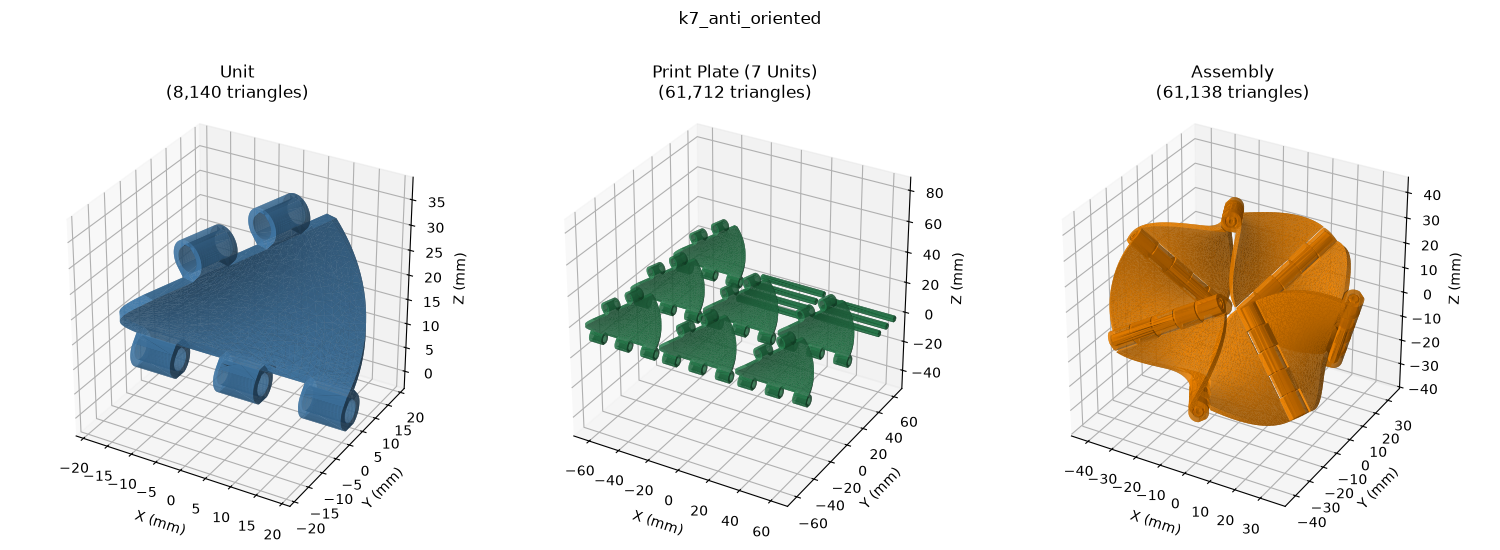

In [8]:
def load_binary_stl_triangles(path: Path) -> np.ndarray:
    data = path.read_bytes()
    n_tri = struct.unpack("<I", data[80:84])[0]
    tri_dtype = np.dtype(
        [
            ("normal", "<f4", (3,)),
            ("verts", "<f4", (3, 3)),
            ("attr", "<u2"),
        ]
    )
    records = np.frombuffer(data, dtype=tri_dtype, count=n_tri, offset=84)
    return records["verts"].astype(float)


def plot_stl_mesh(ax, path: Path, title: str, color: str = "steelblue") -> None:
    tris = load_binary_stl_triangles(path)
    coll = Poly3DCollection(
        tris,
        facecolors=color,
        alpha=0.85,
        shade=True,
    )
    ax.add_collection3d(coll)
    pts = tris.reshape(-1, 3)
    mins = pts.min(axis=0)
    maxs = pts.max(axis=0)
    center = 0.5 * (mins + maxs)
    half = 0.5 * float(np.max(maxs - mins))
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] - half, center[1] + half)
    ax.set_zlim(center[2] - half, center[2] + half)
    ax.set_box_aspect([1, 1, 1])
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.set_zlabel("Z (mm)")
    ax.set_title(f"{title}\n({len(tris):,} triangles)")


fig = plt.figure(figsize=(15, 5.5))
for index, (kind, title, color) in enumerate(
    (
        ("unit", "Unit", "steelblue"),
        ("plate", f"Print Plate ({kc.n} Units)", "seagreen"),
        ("assembly", "Assembly", "darkorange"),
    ),
    start=1,
):
    ax = fig.add_subplot(1, 3, index, projection="3d")
    plot_stl_mesh(ax, output_path(kind, "stl"), title, color=color)
fig.suptitle(f"{prefix}{suffix}")
fig.subplots_adjust(left=0.02, right=0.96, bottom=0.04, top=0.82, wspace=0.2)
plt.show()